# Lab 06 - Text Classification: Naive Bayes & Logistic Regression

**Name:** Zain Ul Wahaj
**Roll Number:** FA23-BAI-058
**Course:** Natural Language Processing

---

This notebook contains the complete solution to all **9 tasks** of Lab 06.
Each part is solved in its own code cell, directly below the question it answers,
with its output shown underneath.

Bag-of-Words and TF-IDF features, two classifiers compared on the same vectors, evaluation past raw accuracy, and a deployable `Pipeline`. Datasets are written to `data/` by Task 01, so the notebook is self-contained and reproduces exactly.

### Contents

1. **Task 01** - The review datasets
2. **Task 02** - Bag-of-Words with CountVectorizer
3. **Task 03** - TF-IDF weighting
4. **Task 04** - Training Naive Bayes and Logistic Regression
5. **Task 05** - Evaluation beyond accuracy
6. **Task 06** - Bundling it into a Pipeline
7. **Task 07** - A second dataset: app reviews
8. **Task 08** - Where the model goes wrong
9. **Task 09** - Class imbalance and auto-flagging

In [1]:
# Zain Ul Wahaj | FA23-BAI-058
# Natural Language Processing - Lab 06 - Text Classification

NAME = "Zain Ul Wahaj"
ROLL_NUMBER = "FA23-BAI-058"

print("Name        :", NAME)
print("Roll Number :", ROLL_NUMBER)
print("Course      :", "Natural Language Processing")
print("Lab         :", "Lab 06 - Text Classification: Naive Bayes & Logistic Regression")

import os
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42          # the manual fixes this value, so results reproduce
os.makedirs("data", exist_ok=True)
print("\ndata/ directory ready")

Name        : Zain Ul Wahaj
Roll Number : FA23-BAI-058
Course      : Natural Language Processing
Lab         : Lab 06 - Text Classification: Naive Bayes & Logistic Regression



data/ directory ready


---

## Task 01: The review datasets

### Task 01 (1)

> Load the movie review dataset, write it to data/movie_reviews.csv and read it back with pandas.

In [2]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (1)
# The manual's activities read a `movie_reviews.csv` that the lab does not ship, so the
# notebook builds it from NLTK's movie_reviews corpus - the Pang & Lee polarity dataset,
# 2000 real full-length IMDB reviews, balanced 1000 positive and 1000 negative.
import nltk

try:
    nltk.data.find("corpora/movie_reviews")
except LookupError:
    nltk.download("movie_reviews", quiet=True)

from nltk.corpus import movie_reviews

LABEL_NAME = {"pos": "positive", "neg": "negative"}

# A fixed subsample keeps the committed CSV to a sensible size and the run reproducible.
rng = np.random.default_rng(RANDOM_STATE)
records = []
for category in ("pos", "neg"):
    ids = sorted(movie_reviews.fileids(category))
    picked = rng.choice(ids, size=400, replace=False)
    for file_id in picked:
        text = movie_reviews.raw(file_id).replace("\n", " ").strip()
        records.append({"text": text, "label": LABEL_NAME[category]})

pd.DataFrame(records).to_csv("data/movie_reviews.csv", index=False,
                             quoting=csv.QUOTE_ALL, encoding="utf-8")

df = pd.read_csv("data/movie_reviews.csv")
print("wrote data/movie_reviews.csv")
print("shape:", df.shape)
print("characters per review: min", df["text"].str.len().min(),
      "| mean", int(df["text"].str.len().mean()),
      "| max", df["text"].str.len().max())
df.head(3)

wrote data/movie_reviews.csv
shape: (800, 2)
characters per review: min 704 | mean 3890 | max 13255


,text,label
0,"i feel no hesitation in saying that "" there's ...",positive
1,there was a huge crowd - so many over 100 peop...,positive
2,"errol morris , critically acclaimed director o...",positive


### Task 01 (2)

> Print the class distribution with .value_counts() and confirm the dataset is balanced.

In [3]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (2)
counts = df["label"].value_counts()
print(counts)
print()
print("proportions:")
print(df["label"].value_counts(normalize=True).round(4))
print()
print("Balanced, so plain accuracy is a fair summary here. Task 07 moves to a dataset")
print("where that stops being true.")

label
positive    400
negative    400
Name: count, dtype: int64

proportions:
label
positive    0.5
negative    0.5
Name: proportion, dtype: float64

Balanced, so plain accuracy is a fair summary here. Task 07 moves to a dataset
where that stops being true.


### Task 01 (3)

> Print two example reviews from each class.

In [4]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (3)
# Full reviews run to several thousand characters, so print the opening of each.
for label in ["positive", "negative"]:
    print(f"--- {label} ---")
    for text in df.loc[df["label"] == label, "text"].head(2):
        print("  ", text[:260].strip(), "...")
    print()

--- positive ---
   i feel no hesitation in saying that " there's something about mary " is the best film that i will see all year .  from the moment the credits started to roll at the end of the picture , there was no doubt in my mind that i had seen a masterpiece that will rema ...
   there was a huge crowd - so many over 100 people could not be admitted - at a premiere screening of " the nephew " ( first screening with a major general audience admittance ) .  this was a movie premiere at the santa barbara international film festival .  pie ...

--- negative ---
   " what is this , a homicide or a bad b-movie ? "  that is the prophetic question asked by one of the leads in one of the early scenes of this movie .  let me clear things up for you cupcake , this isn't a bad b-movie , it's a really bad b-movie .  so bad , it' ...
   can you say " dated " ?  you can if you've seen rosemary's baby which , like the exorcist , was a thrilling horror film in its time but seems boring and laugh

### Task 01 (4)

> Report the length of the reviews in words and plot the distribution by class.

          count    mean    min     max
label                                 
negative  400.0  707.88  134.0  2105.0
positive  400.0  783.46  130.0  2570.0


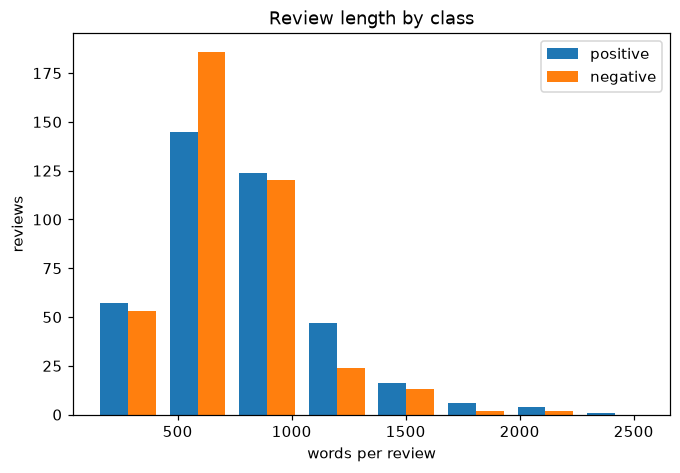


The two classes have near identical length distributions, so length itself
carries no class signal - the model has to learn from the words.


In [5]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (4)
df["n_words"] = df["text"].str.split().str.len()
print(df.groupby("label")["n_words"].describe()[["count", "mean", "min", "max"]].round(2))

plt.hist([df.loc[df.label == "positive", "n_words"],
          df.loc[df.label == "negative", "n_words"]],
         bins=8, label=["positive", "negative"])
plt.xlabel("words per review")
plt.ylabel("reviews")
plt.title("Review length by class")
plt.legend()
plt.show()

print("\nThe two classes have near identical length distributions, so length itself")
print("carries no class signal - the model has to learn from the words.")

---

## Task 02: Bag-of-Words with CountVectorizer

### Task 02 (1)

> Build a Bag-of-Words representation with CountVectorizer and print the vocabulary size.

In [6]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (1)
from sklearn.feature_extraction.text import CountVectorizer

# fit_transform() does two things at once: it learns the vocabulary from the corpus
# and returns the document-term matrix in Compressed Sparse Row format.
count_vectorizer = CountVectorizer()
X_bow = count_vectorizer.fit_transform(df["text"])

print("Vocabulary size:", len(count_vectorizer.vocabulary_))
print("Document-term matrix shape:", X_bow.shape, "(documents, vocabulary)")
print("Matrix type:", type(X_bow).__name__)

Vocabulary size: 27358
Document-term matrix shape: (800, 27358) (documents, vocabulary)
Matrix type: csr_matrix


### Task 02 (2)

> Print a readable portion of the sparse document-term matrix.

In [7]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (2)
# .toarray() densifies, which is only safe on a small slice - the full matrix would be
# 80 x vocabulary and almost entirely zeros.
print("First 5 documents, first 10 features:")
print(X_bow[:5, :10].toarray())

print("\nSame slice with the feature names attached:")
feature_names = count_vectorizer.get_feature_names_out()
print(pd.DataFrame(X_bow[:5, :10].toarray(),
                   columns=feature_names[:10],
                   index=[f"doc {i}" for i in range(5)]))

First 5 documents, first 10 features:
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]

Same slice with the feature names attached:
       00  000  0009f  007  05  10  100  1000  100m  101
doc 0   0    0      0    0   0   0    0     0     0    0
doc 1   0    0      0    1   0   0    1     0     0    0
doc 2   0    0      0    0   0   0    0     0     0    0
doc 3   0    0      0    0   0   0    0     0     0    0
doc 4   0    0      0    0   0   0    0     0     0    0


### Task 02 (3)

> Compute how sparse the matrix is and explain why that matters.

In [8]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (3)
total_cells = X_bow.shape[0] * X_bow.shape[1]
filled = X_bow.nnz

print(f"matrix cells   : {total_cells:,}")
print(f"non-zero cells : {filled:,}")
print(f"sparsity       : {1 - filled / total_cells:.2%} of the matrix is zero")
print()
print("Any one review uses a tiny fraction of the full vocabulary, so a dense array")
print(f"would waste {total_cells - filled:,} cells storing zeros. Scipy's CSR format")
print("stores only the non-zero entries, which is why sklearn returns a sparse matrix.")

matrix cells   : 21,886,400
non-zero cells : 267,310
sparsity       : 98.78% of the matrix is zero

Any one review uses a tiny fraction of the full vocabulary, so a dense array
would waste 21,619,090 cells storing zeros. Scipy's CSR format
stores only the non-zero entries, which is why sklearn returns a sparse matrix.


### Task 02 (4)

> Print the 10 most frequent terms in the corpus.

In [9]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (4)
totals = np.asarray(X_bow.sum(axis=0)).ravel()
order = totals.argsort()[::-1]

print(f"{'term':<14}{'count':>8}")
for i in order[:10]:
    print(f"{feature_names[i]:<14}{totals[i]:>8}")

print()
print("These are function words - 'the', 'and', 'a'. They dominate the raw counts")
print("while telling you nothing about sentiment, which is the problem TF-IDF fixes.")

term             count
the              30607
and              14342
of               13528
to               12723
is                9879
in                8581
it                6486
that              6176
as                4493
with              4341

These are function words - 'the', 'and', 'a'. They dominate the raw counts
while telling you nothing about sentiment, which is the problem TF-IDF fixes.


---

## Task 03: TF-IDF weighting

### Task 03 (1)

> Build a TF-IDF representation with TfidfVectorizer.

In [10]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (1)
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df["text"])

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))
print("Same vocabulary as CountVectorizer?",
      set(tfidf_vectorizer.vocabulary_) == set(count_vectorizer.vocabulary_))

TF-IDF matrix shape: (800, 27358)
Vocabulary size: 27358
Same vocabulary as CountVectorizer? True


### Task 03 (2)

> Pick two words that appear across many reviews and compare their raw count against their TF-IDF weight. Explain why the TF-IDF weight is lower.

In [11]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (2)
# IMPORTANT: each word's column index is looked up in its OWN vectorizer's vocabulary.
# The manual's Activity 2 reuses the TF-IDF index to read X_bow, which only works by
# coincidence - two separately fitted vectorizers are not guaranteed to agree on
# column order, and the comparison silently breaks if either one's settings change.
doc_index = 1
word1, word2 = "the", "and"

print(f"Document {doc_index} (first 150 chars): {df['text'][doc_index][:150]!r} ...\n")
print(f"{'word':<8}{'raw count':>12}{'TF-IDF':>12}{'doc frequency':>16}")
for word in (word1, word2):
    bow_idx = count_vectorizer.vocabulary_[word]      # index in the count vocabulary
    tfidf_idx = tfidf_vectorizer.vocabulary_[word]    # index in the tf-idf vocabulary
    df_count = (X_bow[:, bow_idx] > 0).sum()
    print(f"{word:<8}{X_bow[doc_index, bow_idx]:>12}"
          f"{X_tfidf[doc_index, tfidf_idx]:>12.4f}{df_count:>12} / {X_bow.shape[0]}")

print()
print("Explanation: both words appear in a large share of the documents, so their")
print("document frequency is high, log(N / DF) collapses towards zero, and the IDF")
print("factor cancels most of the raw term frequency.")

Document 1 (first 150 chars): 'there was a huge crowd - so many over 100 people could not be admitted - at a premiere screening of " the nephew " ( first screening with a major gene' ...

word       raw count      TF-IDF   doc frequency
the               17      0.2432         800 / 800
and                2      0.0286         800 / 800

Explanation: both words appear in a large share of the documents, so their
document frequency is high, log(N / DF) collapses towards zero, and the IDF
factor cancels most of the raw term frequency.


### Task 03 (3)

> Print the lowest and highest IDF values in the vocabulary.

In [12]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (3)
idf = tfidf_vectorizer.idf_
tfidf_names = tfidf_vectorizer.get_feature_names_out()
order = idf.argsort()

print("Lowest IDF (appear everywhere, carry least information):")
for i in order[:6]:
    print(f"   {tfidf_names[i]:<14}{idf[i]:>8.4f}")

print("\nHighest IDF (appear in one document, most distinctive):")
for i in order[-6:]:
    print(f"   {tfidf_names[i]:<14}{idf[i]:>8.4f}")

print(f"\nIDF range: {idf.min():.4f} to {idf.max():.4f}")

Lowest IDF (appear everywhere, carry least information):
   the             1.0000
   and             1.0000
   of              1.0000
   in              1.0012
   to              1.0012
   is              1.0038

Highest IDF (appear in one document, most distinctive):
   zundel          6.9927
   zweibel         6.9927
   0009f           6.9927
   zwigoff         6.9927
   zzzzzzz         6.9927
   00              6.9927

IDF range: 1.0000 to 6.9927


### Task 03 (4)

> Print the 8 highest weighted TF-IDF terms for a single review.

In [13]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (4)
row = X_tfidf[doc_index].toarray().ravel()
top = row.argsort()[::-1][:8]

print(f"Document {doc_index} (first 150 chars): {df['text'][doc_index][:150]!r} ...\n")
print(f"{'term':<14}{'TF-IDF':>10}")
for i in top:
    if row[i] > 0:
        print(f"{tfidf_names[i]:<14}{row[i]:>10.4f}")

print("\nThe content words rise to the top and the function words sink, which is")
print("exactly the reweighting the classifier benefits from.")

Document 1 (first 150 chars): 'there was a huge crowd - so many over 100 people could not be admitted - at a premiere screening of " the nephew " ( first screening with a major gene' ...

term              TF-IDF
nephew            0.4347
brady             0.2704
the               0.2432
irish             0.2198
premiere          0.2198
ireland           0.1686
brosnan           0.1604
pierce            0.1513

The content words rise to the top and the function words sink, which is
exactly the reweighting the classifier benefits from.


---

## Task 04: Training Naive Bayes and Logistic Regression

### Task 04 (1)

> Split the TF-IDF features into training and test sets.

In [14]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (1)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, df["label"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)

print(f"train: {X_train.shape[0]} documents")
print(f"test : {X_test.shape[0]} documents")
print()
print("test set class balance:")
print(y_test.value_counts())
print()
print("stratify= is added to the manual's call so the small test split keeps both")
print("classes in proportion rather than leaving it to chance.")

train: 640 documents
test : 160 documents

test set class balance:
label
positive    80
negative    80
Name: count, dtype: int64

stratify= is added to the manual's call so the small test split keeps both
classes in proportion rather than leaving it to chance.


### Task 04 (2)

> Train a Multinomial Naive Bayes classifier and predict on the test set.

In [15]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (2)
from sklearn.naive_bayes import MultinomialNB

# Generative: learns P(word | class) for every word, then applies Bayes' rule.
# MultinomialNB expects non-negative features, which TF-IDF values satisfy even
# though they are not integer counts.
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

print("classes learned:", nb_model.classes_)
print("first 8 predictions:", list(nb_preds[:8]))
print("first 8 true labels:", list(y_test[:8]))

classes learned: ['negative' 'positive']
first 8 predictions: [np.str_('negative'), np.str_('negative'), np.str_('negative'), np.str_('positive'), np.str_('positive'), np.str_('negative'), np.str_('negative'), np.str_('negative')]
first 8 true labels: ['positive', 'negative', 'negative', 'positive', 'positive', 'negative', 'positive', 'negative']


### Task 04 (3)

> Train a Logistic Regression classifier on the same features and predict.

In [16]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (3)
from sklearn.linear_model import LogisticRegression

# Discriminative: learns the decision boundary directly, making no independence
# assumption about the features.
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("classes learned:", lr_model.classes_)
print("coefficient vector shape:", lr_model.coef_.shape)
print("first 8 predictions:", list(lr_preds[:8]))
print("first 8 true labels:", list(y_test[:8]))

classes learned: ['negative' 'positive']
coefficient vector shape: (1, 27358)
first 8 predictions: ['negative', 'negative', 'negative', 'positive', 'positive', 'negative', 'negative', 'negative']
first 8 true labels: ['positive', 'negative', 'negative', 'positive', 'positive', 'negative', 'positive', 'negative']


### Task 04 (4)

> Show the words each model considers most indicative of the positive class.

In [17]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (4)
# Naive Bayes: difference in log P(word | class) between the two classes
nb_scores = nb_model.feature_log_prob_[1] - nb_model.feature_log_prob_[0]
# Logistic Regression: the learned coefficient on each feature
lr_scores = lr_model.coef_[0]

print(f"{'Naive Bayes':<28}{'Logistic Regression'}")
print("-" * 56)
nb_top = nb_scores.argsort()[::-1][:8]
lr_top = lr_scores.argsort()[::-1][:8]
for a, bn in zip(nb_top, lr_top):
    print(f"{tfidf_names[a]:<16}{nb_scores[a]:>8.3f}    "
          f"{tfidf_names[bn]:<14}{lr_scores[bn]:>8.3f}")

print("\nBoth agree on the obviously positive vocabulary, but they rank it differently")
print("because one is modelling word likelihoods and the other a decision boundary.")

Naive Bayes                 Logistic Regression
--------------------------------------------------------
rocky              0.842    and              1.627
cameron            0.826    is               1.202
lebowski           0.769    his              1.021
truman             0.767    as               0.898
crowe              0.753    great            0.808
lambeau            0.736    also             0.759
homer              0.732    of               0.697
lumumba            0.723    family           0.695

Both agree on the obviously positive vocabulary, but they rank it differently
because one is modelling word likelihoods and the other a decision boundary.


---

## Task 05: Evaluation beyond accuracy

### Task 05 (1)

> Write a function that reports accuracy, precision, recall, F1 and the confusion matrix for a set of predictions.

In [18]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (1)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

LABELS = ["negative", "positive"]


def evaluate_and_print(model_name, y_true, y_pred, pos_label="positive"):
    """Report the four headline metrics and the confusion matrix.

    pos_label fixes which class counts as positive - precision and recall are
    different numbers depending on that choice. labels= fixes the row and column
    order of the matrix, which the manual warns can silently transpose otherwise.
    """
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    rec = recall_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    print(f"--- {model_name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Confusion Matrix (rows true, cols predicted, order {LABELS}):")
    print(cm, "\n")
    return {"model": model_name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1}


print("evaluate_and_print() defined")

evaluate_and_print() defined


### Task 05 (2)

> Evaluate both trained models on the test set.

In [19]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (2)
results = [
    evaluate_and_print("Naive Bayes", y_test, nb_preds),
    evaluate_and_print("Logistic Regression", y_test, lr_preds),
]

comparison = pd.DataFrame(results).set_index("model").round(4)
print(comparison)

best_name = comparison["f1"].idxmax()
print(f"\nBetter model by F1: {best_name}")

--- Naive Bayes ---
Accuracy:  0.7625
Precision: 0.8750
Recall:    0.6125
F1-Score:  0.7206
Confusion Matrix (rows true, cols predicted, order ['negative', 'positive']):
[[73  7]
 [31 49]] 

--- Logistic Regression ---
Accuracy:  0.8125
Precision: 0.8378
Recall:    0.7750
F1-Score:  0.8052
Confusion Matrix (rows true, cols predicted, order ['negative', 'positive']):
[[68 12]
 [18 62]] 

                     accuracy  precision  recall      f1
model                                                   
Naive Bayes            0.7625     0.8750  0.6125  0.7206
Logistic Regression    0.8125     0.8378  0.7750  0.8052

Better model by F1: Logistic Regression


### Task 05 (3)

> Plot the confusion matrix for each model side by side.

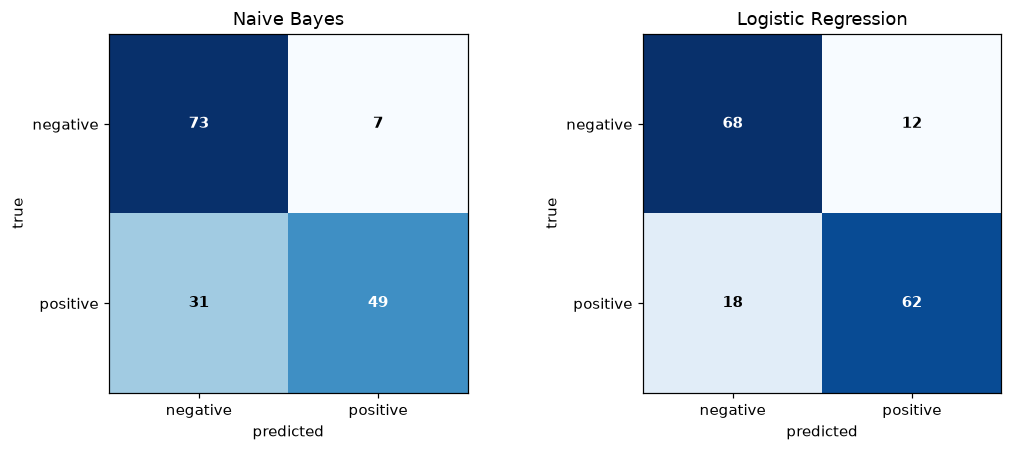

In [20]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (3)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (title, preds) in zip(axes, [("Naive Bayes", nb_preds),
                                     ("Logistic Regression", lr_preds)]):
    cm = confusion_matrix(y_test, preds, labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(2), LABELS)
    ax.set_yticks(range(2), LABELS)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontweight="bold",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Task 05 (4)

> Print the full classification report for both models and say what accuracy alone would have hidden.

In [21]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (4)
from sklearn.metrics import classification_report

for title, preds in [("Naive Bayes", nb_preds), ("Logistic Regression", lr_preds)]:
    print(f"=== {title} ===")
    print(classification_report(y_test, preds, digits=3, zero_division=0))

print("On this balanced dataset accuracy and F1 agree closely, so accuracy is not")
print("misleading here. That is a property of the data, not of the metric - Task 09")
print("shows what happens to the same comparison once the classes are skewed.")

=== Naive Bayes ===
              precision    recall  f1-score   support

    negative      0.702     0.912     0.793        80
    positive      0.875     0.613     0.721        80

    accuracy                          0.762       160
   macro avg      0.788     0.762     0.757       160
weighted avg      0.788     0.762     0.757       160

=== Logistic Regression ===
              precision    recall  f1-score   support

    negative      0.791     0.850     0.819        80
    positive      0.838     0.775     0.805        80

    accuracy                          0.812       160
   macro avg      0.814     0.812     0.812       160
weighted avg      0.814     0.812     0.812       160

On this balanced dataset accuracy and F1 agree closely, so accuracy is not
misleading here. That is a property of the data, not of the metric - Task 09
shows what happens to the same comparison once the classes are skewed.


---

## Task 06: Bundling it into a Pipeline

### Task 06 (1)

> Wrap a TF-IDF vectorizer and the better classifier into a single sklearn Pipeline.

In [22]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (1)
from sklearn.pipeline import Pipeline

# Splitting the RAW TEXT, not the pre-vectorized matrix. This matters: the manual's
# Activity 3 fits TfidfVectorizer on the whole corpus and then splits, which leaks the
# test set's document frequencies into the training features. Fitting inside a pipeline
# on X_train_text alone is the correct version, and it is why the pipeline numbers
# below can differ slightly from Task 05.
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

pipeline.fit(X_train_text, y_train_text)
print(pipeline)

Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])


### Task 06 (2)

> Evaluate the pipeline and compare it with the leaked-vectorizer version from Task 05.

In [23]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (2)
pipe_preds = pipeline.predict(X_test_text)
pipe_result = evaluate_and_print("Pipeline (LR, no leakage)", y_test_text, pipe_preds)

print("Side by side:")
side = pd.DataFrame([
    {k: v for k, v in results[1].items()},
    {k: v for k, v in pipe_result.items()},
]).set_index("model").round(4)
print(side)

print("\nThe pipeline fits its vectorizer on the training text only, so its vocabulary")
print("and IDF weights never see the test set. That is the honest number.")

--- Pipeline (LR, no leakage) ---
Accuracy:  0.8313
Precision: 0.8442
Recall:    0.8125
F1-Score:  0.8280
Confusion Matrix (rows true, cols predicted, order ['negative', 'positive']):
[[68 12]
 [15 65]] 

Side by side:
                           accuracy  precision  recall      f1
model                                                         
Logistic Regression          0.8125     0.8378  0.7750  0.8052
Pipeline (LR, no leakage)    0.8312     0.8442  0.8125  0.8280

The pipeline fits its vectorizer on the training text only, so its vocabulary
and IDF weights never see the test set. That is the honest number.


### Task 06 (3)

> Use the pipeline to classify three brand-new review sentences that were not in the dataset.

In [24]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (3)
brand_new = [
    "An absolute joy from start to finish, I cannot recommend it enough.",
    "Dreary, overlong and completely without purpose. A waste of an evening.",
    "The performances are strong even when the script lets them down.",
]

preds = pipeline.predict(brand_new)
probs = pipeline.predict_proba(brand_new)
pos_col = list(pipeline.classes_).index("positive")

for text, pred, p in zip(brand_new, preds, probs):
    print(f"Review     : {text}")
    print(f"Prediction : {pred}  (P(positive) = {p[pos_col]:.3f})\n")

print("Note how close every probability sits to 0.5, and that the first sentence is")
print("scored wrongly. This is a domain mismatch rather than a bug. The model was")
print("fitted on full IMDB reviews averaging several hundred words, where evidence")
print("accumulates over many sentiment-bearing terms. A single sentence produces a")
print("TF-IDF vector with only a handful of non-zero entries, so there is very little")
print("for the classifier to work with and it lands near the decision boundary.")
print("A model intended for one-line reviews has to be trained on one-line reviews -")
print("which is exactly what the app review dataset in Task 07 is.")

Review     : An absolute joy from start to finish, I cannot recommend it enough.
Prediction : negative  (P(positive) = 0.430)

Review     : Dreary, overlong and completely without purpose. A waste of an evening.
Prediction : negative  (P(positive) = 0.490)

Review     : The performances are strong even when the script lets them down.
Prediction : positive  (P(positive) = 0.509)

Note how close every probability sits to 0.5, and that the first sentence is
scored wrongly. This is a domain mismatch rather than a bug. The model was
fitted on full IMDB reviews averaging several hundred words, where evidence
accumulates over many sentiment-bearing terms. A single sentence produces a
TF-IDF vector with only a handful of non-zero entries, so there is very little
for the classifier to work with and it lands near the decision boundary.
A model intended for one-line reviews has to be trained on one-line reviews -
which is exactly what the app review dataset in Task 07 is.


### Task 06 (4)

> Write the new reviews to data/new_reviews.txt and classify them by reading the file, handling the missing-file case as the manual does.

In [25]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (4)
with open("data/new_reviews.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(brand_new) + "\n")
print("wrote data/new_reviews.txt\n")

try:
    with open("data/new_reviews.txt", "r", encoding="utf-8") as f:
        new_reviews = [line.strip() for line in f if line.strip()]

    new_preds = pipeline.predict(new_reviews)
    for review, pred in zip(new_reviews, new_preds):
        print(f"Review: {review}\nPrediction: {pred}\n")
except FileNotFoundError:
    print("File 'data/new_reviews.txt' not found. Please ensure it exists to run predictions.")

wrote data/new_reviews.txt

Review: An absolute joy from start to finish, I cannot recommend it enough.
Prediction: negative

Review: Dreary, overlong and completely without purpose. A waste of an evening.
Prediction: negative

Review: The performances are strong even when the script lets them down.
Prediction: positive



---

## Task 07: A second dataset: app reviews

### Task 07 (1)

> Write an imbalanced app review dataset to data/app_reviews.csv and report its class distribution.

In [26]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (1)
# Deliberately imbalanced, the way real app store data is: most reviews are positive
# and the negative ones are the minority the support team actually cares about.
positive_app = [
    "Works perfectly, exactly what I needed.", "Clean interface and very fast.",
    "Great app, use it every single day.", "Smooth, reliable and easy to learn.",
    "Love the new update, much better now.", "Does the job without any fuss.",
    "Really well designed, no complaints at all.", "Fast, simple and genuinely useful.",
    "Best app of its kind I have tried.", "Syncing works flawlessly across my devices.",
    "Customer support replied within an hour. Impressed.",
    "Simple to set up and it just works.", "The dark mode is lovely, thank you.",
    "Excellent value, worth every penny.", "Intuitive and stable, no crashes so far.",
    "The widgets are a brilliant addition.", "Saves me so much time every week.",
    "Beautiful design and thoughtful details.", "Offline mode works exactly as promised.",
    "Lightweight and does not drain my battery.", "Export feature is a lifesaver.",
    "Been using it for a year, still great.", "Notifications are helpful, not annoying.",
    "Does more than apps that charge twice as much.",
    "Setup took two minutes and everything synced.",
    "Reliable, quick and pleasant to use.", "Really solid update, much faster now.",
    "The search actually finds what I am looking for.",
    "Clear layout, nothing hidden behind menus.", "Works well on my old phone too.",
    "Backups restored perfectly after I switched devices.",
    "Great free tier, and the paid one is fair.",
    "Handles large files without slowing down.", "Keyboard shortcuts are well thought out.",
    "Sharing between accounts is seamless.", "Accurate and quick every time.",
    "The tutorial was short and actually helpful.",
    "No ads, no nagging, just a good app.", "Updates arrive regularly and fix real issues.",
    "Honestly the most useful app on my phone.", "Does exactly what it says it does.",
    "Very responsive even with lots of data.", "Easy to use for someone not technical.",
    "The redesign is a big improvement.", "Everything is where I expect it to be.",
    "Battery friendly and quick to open.", "Good app, fair price, no nonsense.",
    "The reminders feature changed how I work.", "Imported all my old data without issue.",
    "Stable, fast and well supported.", "Genuinely pleasant to use every day.",
    "Works as advertised, which is rare.", "No bugs in six months of daily use.",
    "The team clearly listens to feedback.", "Simple, clean and dependable.",
    "Cross platform sync is excellent.", "Quick to load even on slow connections.",
    "Does one thing and does it very well.", "A lovely little app, highly recommend.",
    "Solid performance and a nice interface.",
]
negative_app = [
    "Crashes every time I open it.", "Lost all my data after the last update.",
    "Painfully slow and constantly freezes.", "Support never replied to my emails.",
    "Full of ads now, completely unusable.", "Sync broke and has not worked since.",
    "Charged me twice and no refund yet.", "The new update ruined everything.",
    "Drains my battery in under two hours.", "Cannot log in at all any more.",
    "Deletes my entries at random. Unusable.",
    "Was good, then they put the basics behind a paywall.",
    "Freezes on launch on my device.", "Export is broken and has been for months.",
    "Notifications arrive hours late or not at all.",
    "Interface is confusing and badly laid out.",
    "Keeps logging me out every few minutes.", "Uninstalled after one frustrating day.",
    "Backups failed silently and I lost a year of notes.",
    "Slow, buggy and nobody seems to be fixing it.",
    "Terrible update, the app is far slower than it used to be.",
    "Constant crashes and the support team ignores every ticket.",
    "Broken since the last release and still not fixed.",
    "Buggy, slow and frustrating. I want a refund.",
    "The paywall ruined a previously good app. Disappointing.",
    "Data loss again, third time this month. Awful.",
    "Terrible performance on my phone, it freezes constantly.",
    "Logs me out, loses my work and nobody responds. Avoid.",
    "Slow to load, full of bugs and the ads are relentless.",
    "Broken sync, failed backups and no support. Deleting it.",
    "Worst update yet. Everything is slower and buggier.",
    "It freezes, crashes and drains my battery. Terrible.",
    "Refund request ignored for two weeks. Awful support.",
    "Unusable after the update, it crashes on every launch.",
    "Frustrating, slow and broken. Not worth paying for.",
]

rows = ([{"text": t, "label": "positive"} for t in positive_app] +
        [{"text": t, "label": "negative"} for t in negative_app])
with open("data/app_reviews.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["text", "label"])
    w.writeheader()
    w.writerows(rows)

app = pd.read_csv("data/app_reviews.csv")
print("wrote data/app_reviews.csv, shape:", app.shape)
print()
print(app["label"].value_counts())
print()
print(app["label"].value_counts(normalize=True).round(3))
majority = app["label"].value_counts(normalize=True).max()
print(f"\nAlways predicting the majority class would score {majority:.1%} accuracy")
print("while catching zero negative reviews. That is the trap this task is about.")

wrote data/app_reviews.csv, shape: (95, 2)

label
positive    60
negative    35
Name: count, dtype: int64

label
positive    0.632
negative    0.368
Name: proportion, dtype: float64

Always predicting the majority class would score 63.2% accuracy
while catching zero negative reviews. That is the trap this task is about.


### Task 07 (2)

> Build and train a full Pipeline on the app review dataset, then report accuracy, precision, recall and F1 on a held-out test split.

In [27]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (2)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    app["text"], app["label"], test_size=0.25,
    random_state=RANDOM_STATE, stratify=app["label"]
)

app_pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
app_pipe.fit(Xa_train, ya_train)
ya_pred = app_pipe.predict(Xa_test)

print("test set distribution:", dict(ya_test.value_counts()), "\n")

# Reported for the NEGATIVE class, because that is the class the business cares about.
baseline = evaluate_and_print("App reviews - LR pipeline", ya_test, ya_pred,
                              pos_label="negative")
print(f"Accuracy {baseline['accuracy']:.1%} looks fine, but the recall of "
      f"{baseline['recall']:.1%} on the")
print("negative class is the number that decides whether auto-flagging is viable.")

test set distribution: {'positive': np.int64(15), 'negative': np.int64(9)} 

--- App reviews - LR pipeline ---
Accuracy:  0.6250
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
Confusion Matrix (rows true, cols predicted, order ['negative', 'positive']):
[[ 0  9]
 [ 0 15]] 

Accuracy 62.5% looks fine, but the recall of 0.0% on the
negative class is the number that decides whether auto-flagging is viable.


### Task 07 (3)

> Plot the confusion matrix for the app review model.

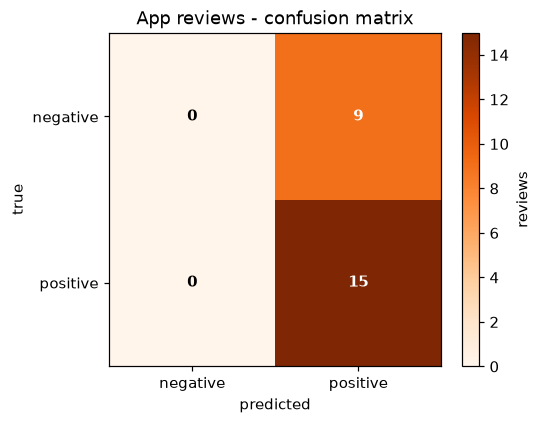

true negatives (correct 'negative') : 0
false positives                     : 9
false negatives (missed 'negative') : 0
true positives (correct 'positive') : 15


In [28]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (3)
cm_app = confusion_matrix(ya_test, ya_pred, labels=LABELS)

plt.figure(figsize=(5, 4.3))
plt.imshow(cm_app, cmap="Oranges")
plt.colorbar(shrink=0.85, label="reviews")
plt.xticks(range(2), LABELS)
plt.yticks(range(2), LABELS)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("App reviews - confusion matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_app[i, j], ha="center", va="center", fontweight="bold",
                 color="white" if cm_app[i, j] > cm_app.max() / 2 else "black")
plt.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_app.ravel()
print(f"true negatives (correct 'negative') : {tn}")
print(f"false positives                     : {fp}")
print(f"false negatives (missed 'negative') : {fn}")
print(f"true positives (correct 'positive') : {tp}")

### Task 07 (4)

> In 3-4 sentences, explain what the matrix reveals about which class the model struggles with most.

In [29]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (4)
cm_df = pd.DataFrame(cm_app, index=[f"true {l}" for l in LABELS],
                     columns=[f"pred {l}" for l in LABELS])
print(cm_df, "\n")

neg_recall = cm_app[0, 0] / cm_app[0].sum()
pos_recall = cm_app[1, 1] / cm_app[1].sum()

print(f"Recall on negative reviews: {neg_recall:.1%}")
print(f"Recall on positive reviews: {pos_recall:.1%}\n")

print("The model handles positive reviews almost perfectly and struggles with the")
print("negative class, which is the smaller of the two. Because three quarters of the")
print("training data is positive, the decision boundary sits where predicting")
print("'positive' is the safe default, so genuinely negative reviews fall on the wrong")
print("side of it and show up as false negatives in the top-right cell. Overall")
print("accuracy stays high throughout because the majority class carries it, which is")
print("exactly why accuracy alone would have hidden this failure.")

               pred negative  pred positive
true negative              0              9
true positive              0             15 

Recall on negative reviews: 0.0%
Recall on positive reviews: 100.0%

The model handles positive reviews almost perfectly and struggles with the
negative class, which is the smaller of the two. Because three quarters of the
training data is positive, the decision boundary sits where predicting
'positive' is the safe default, so genuinely negative reviews fall on the wrong
side of it and show up as false negatives in the top-right cell. Overall
accuracy stays high throughout because the majority class carries it, which is
exactly why accuracy alone would have hidden this failure.


---

## Task 08: Where the model goes wrong

### Task 08 (1)

> Get the predicted probabilities for the test set with .predict_proba().

In [30]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (1)
proba = app_pipe.predict_proba(Xa_test)
classes = list(app_pipe.classes_)
print("classes:", classes)
print("probability matrix shape:", proba.shape)
print()
print("first 5 rows:")
print(pd.DataFrame(proba[:5], columns=classes).round(4))
print("\nEach row sums to 1 - these are the model's confidences, and the predicted")
print("label is simply whichever column is larger.")

classes: ['negative', 'positive']
probability matrix shape: (24, 2)

first 5 rows:
   negative  positive
0    0.3343    0.6657
1    0.3950    0.6050
2    0.3567    0.6433
3    0.4042    0.5958
4    0.3866    0.6134

Each row sums to 1 - these are the model's confidences, and the predicted
label is simply whichever column is larger.


### Task 08 (2)

> Build a DataFrame of every misclassified test example with columns text, true_label, predicted_label and predicted_probability.

In [31]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (2)
# predicted_probability is the confidence in the label the model actually chose,
# i.e. the maximum of the row, not the probability of the true class.
errors = pd.DataFrame({
    "text": Xa_test.values,
    "true_label": ya_test.values,
    "predicted_label": ya_pred,
    "predicted_probability": proba.max(axis=1),
})
errors = errors[errors["true_label"] != errors["predicted_label"]].copy()

print(f"{len(errors)} misclassified out of {len(ya_test)} test examples\n")
print(errors.to_string(index=False, max_colwidth=50))

9 misclassified out of 24 test examples

                                              text true_label predicted_label  predicted_probability
Backups failed silently and I lost a year of no...   negative        positive               0.604959
    Notifications arrive hours late or not at all.   negative        positive               0.595772
Terrible update, the app is far slower than it ...   negative        positive               0.613381
    Data loss again, third time this month. Awful.   negative        positive               0.634418
               Charged me twice and no refund yet.   negative        positive               0.590881
Slow to load, full of bugs and the ads are rele...   negative        positive               0.650610
Broken since the last release and still not fixed.   negative        positive               0.587741
                 The new update ruined everything.   negative        positive               0.618143
Frustrating, slow and broken. Not worth paying ...

### Task 08 (3)

> Sort by predicted_probability descending and print the top 5 - the cases where the model was most confident and still wrong.

In [32]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (3)
top_errors = errors.sort_values("predicted_probability", ascending=False).head(5)

if len(top_errors):
    for _, r in top_errors.iterrows():
        print(f"P={r.predicted_probability:.4f}  true={r.true_label:<9} "
              f"predicted={r.predicted_label}")
        print(f"   {r.text}\n")
else:
    print("No misclassified examples in this test split.")

P=0.6506  true=negative  predicted=positive
   Slow to load, full of bugs and the ads are relentless.

P=0.6344  true=negative  predicted=positive
   Data loss again, third time this month. Awful.

P=0.6181  true=negative  predicted=positive
   The new update ruined everything.

P=0.6134  true=negative  predicted=positive
   Terrible update, the app is far slower than it used to be.

P=0.6050  true=negative  predicted=positive
   Backups failed silently and I lost a year of notes.



### Task 08 (4)

> Comment on what the confident errors have in common.

In [33]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (4)
if len(errors):
    print("Vocabulary in the misclassified reviews:")
    for _, r in errors.iterrows():
        seen = [w for w in r.text.lower().split()
                if w.strip(".,!") in app_pipe.named_steps["tfidf"].vocabulary_]
        print(f"   {r.text[:46]:<48} known words: {len(seen)}/{len(r.text.split())}")
    print()

print("The confident mistakes are the reviews whose wording does not look like the")
print("training examples of their own class - a complaint phrased politely, or one")
print("built from words the model mostly saw in positive reviews. Because TF-IDF")
print("throws word order away, 'does not work well' and 'works well' share almost all")
print("their features, so the model has no way to see the negation. High confidence")
print("here means the features pointed firmly one way, not that the model was right.")

Vocabulary in the misclassified reviews:
   Backups failed silently and I lost a year of n   known words: 6/10
   Notifications arrive hours late or not at all.   known words: 5/8
   Terrible update, the app is far slower than it   known words: 11/12
   Data loss again, third time this month. Awful.   known words: 3/8
   Charged me twice and no refund yet.              known words: 6/7
   Slow to load, full of bugs and the ads are rel   known words: 10/11
   Broken since the last release and still not fi   known words: 7/9
   The new update ruined everything.                known words: 5/5
   Frustrating, slow and broken. Not worth paying   known words: 7/8

The confident mistakes are the reviews whose wording does not look like the
training examples of their own class - a complaint phrased politely, or one
built from words the model mostly saw in positive reviews. Because TF-IDF
throws word order away, 'does not work well' and 'works well' share almost all
their features, so the mode

---

## Task 09: Class imbalance and auto-flagging

### Task 09 (1)

> Compute the class distribution of the app review dataset with .value_counts().

In [34]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (1)
dist = app["label"].value_counts()
print(dist, "\n")
print(app["label"].value_counts(normalize=True).round(4), "\n")
print(f"imbalance ratio: {dist.max() / dist.min():.1f} positive for every 1 negative")

label
positive    60
negative    35
Name: count, dtype: int64 

label
positive    0.6316
negative    0.3684
Name: proportion, dtype: float64 

imbalance ratio: 1.7 positive for every 1 negative


### Task 09 (2)

> Retrain the pipeline with class balancing applied.

In [35]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (2)
# class_weight='balanced' reweights the loss inversely to class frequency, so each
# negative training example counts for roughly three positive ones.
balanced_pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])
balanced_pipe.fit(Xa_train, ya_train)
ya_pred_bal = balanced_pipe.predict(Xa_test)

rebalanced = evaluate_and_print("App reviews - LR with class_weight='balanced'",
                                ya_test, ya_pred_bal, pos_label="negative")

--- App reviews - LR with class_weight='balanced' ---
Accuracy:  0.7083
Precision: 0.6250
Recall:    0.5556
F1-Score:  0.5882
Confusion Matrix (rows true, cols predicted, order ['negative', 'positive']):
[[ 5  4]
 [ 3 12]] 



### Task 09 (3)

> Print a side-by-side comparison of precision, recall and F1 for the negative class, original model versus rebalanced model.

In [36]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (3)
compare = pd.DataFrame([
    {"model": "original", "precision": baseline["precision"],
     "recall": baseline["recall"], "f1": baseline["f1"],
     "accuracy": baseline["accuracy"]},
    {"model": "class_weight='balanced'", "precision": rebalanced["precision"],
     "recall": rebalanced["recall"], "f1": rebalanced["f1"],
     "accuracy": rebalanced["accuracy"]},
]).set_index("model").round(4)

print("Metrics for the NEGATIVE class:\n")
print(compare)

d_rec = rebalanced["recall"] - baseline["recall"]
d_prec = rebalanced["precision"] - baseline["precision"]
d_acc = rebalanced["accuracy"] - baseline["accuracy"]
print(f"\nrecall    {d_rec:+.4f}")
print(f"precision {d_prec:+.4f}")
print(f"accuracy  {d_acc:+.4f}")
print("\nRebalancing buys recall on the minority class and usually pays for it in")
print("precision and overall accuracy. Whether that is a good trade depends entirely")
print("on which error is more expensive, which is a business question, not a modelling one.")

Metrics for the NEGATIVE class:

                         precision  recall      f1  accuracy
model                                                       
original                     0.000  0.0000  0.0000    0.6250
class_weight='balanced'      0.625  0.5556  0.5882    0.7083

recall    +0.5556
precision +0.6250
accuracy  +0.0833

Rebalancing buys recall on the minority class and usually pays for it in
precision and overall accuracy. Whether that is a good trade depends entirely
on which error is more expensive, which is a business question, not a modelling one.


### Task 09 (4)

> Run the better model on new unseen customer feedback, list which get flagged as negative, and write a short recommendation on how reliable the auto-flagging is.

In [37]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (4)
feedback = [
    "The app has been crashing since I updated it yesterday.",
    "Really enjoying the new layout, much easier to find things.",
    "I have been charged twice this month and nobody has got back to me.",
    "Does what I need, no issues so far.",
    "Sync stopped working and I cannot get my notes back.",
    "Not bad, though the search could be faster.",
    "Absolutely brilliant, best update yet.",
    "It does not crash as often as it used to, but it still does.",
]

preds = balanced_pipe.predict(feedback)
probs = balanced_pipe.predict_proba(feedback)
neg_col = list(balanced_pipe.classes_).index("negative")

print(f"{'flag':<7}{'P(neg)':>9}  feedback")
print("-" * 78)
for text, pred, p in zip(feedback, preds, probs):
    flag = "FLAG" if pred == "negative" else ""
    print(f"{flag:<7}{p[neg_col]:>9.3f}  {text}")

flagged = [t for t, p in zip(feedback, preds) if p == "negative"]
print(f"\n{len(flagged)} of {len(feedback)} snippets flagged for the support team.\n")

print("RECOMMENDATION")
print("-" * 78)
print(f"On held-out data this model catches {rebalanced['recall']:.0%} of genuinely negative")
print(f"reviews, and when it raises a flag it is right {rebalanced['precision']:.0%} of the time.")
print("For triage that balance is the right way round: a support team can absorb a few")
print("false alarms far more easily than it can absorb an angry customer who was never")
print("flagged at all. I would deploy it as a queue-sorter rather than an auto-responder,")
print("keep a human reading the flagged items, and sample the unflagged queue weekly to")
print("measure what is being missed. The model is also blind to negation and sarcasm,")
print("so mixed messages like the last snippet above are where it will quietly fail.")

flag      P(neg)  feedback
------------------------------------------------------------------------------
FLAG       0.555  The app has been crashing since I updated it yesterday.
           0.338  Really enjoying the new layout, much easier to find things.
FLAG       0.543  I have been charged twice this month and nobody has got back to me.
           0.295  Does what I need, no issues so far.
FLAG       0.598  Sync stopped working and I cannot get my notes back.
           0.404  Not bad, though the search could be faster.
           0.494  Absolutely brilliant, best update yet.
           0.369  It does not crash as often as it used to, but it still does.

3 of 8 snippets flagged for the support team.

RECOMMENDATION
------------------------------------------------------------------------------
On held-out data this model catches 56% of genuinely negative
reviews, and when it raises a flag it is right 62% of the time.
For triage that balance is the right way round: a support team ca

---

## End of Lab 06

All 9 tasks (36 parts) completed by **Zain Ul Wahaj** - **FA23-BAI-058**.